In [2]:
from pathlib import Path
import sys
import json
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Project paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "comparison" else Path.cwd()

ML_SRC = PROJECT_ROOT / "machine-learning" / "src"
DL_SRC = PROJECT_ROOT / "deep-learning" / "src"

ML_MODEL_PATH = PROJECT_ROOT / "machine-learning" / "models" / "sentiment_model.joblib"
DL_MODEL_PATH = PROJECT_ROOT / "deep-learning" / "models" / "sentiment_lstm.pth"
VOCAB_PATH = PROJECT_ROOT / "deep-learning" / "models" / "vocab.json"

# Device for PyTorch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE)
print("ML model exists:", ML_MODEL_PATH.exists())
print("DL model exists:", DL_MODEL_PATH.exists())
print("Vocabulary exists:", VOCAB_PATH.exists())

Project root: d:\Python\Github_P\sentiment-analysis-deep-learning
Device: cuda
ML model exists: True
DL model exists: True
Vocabulary exists: True


In [3]:
# Add project source directories to Python's import path
sys.path.insert(0, str(ML_SRC))
sys.path.insert(0, str(DL_SRC))

import joblib

from model import SentimentLSTM
from preprocess import encode, pad_or_truncate

# Load the Machine Learning model
ml_model = joblib.load(ML_MODEL_PATH)

# Load the Deep Learning vocabulary
with open(VOCAB_PATH, "r", encoding="utf-8") as file:
    vocab = json.load(file)

# Build the LSTM architecture
dl_model = SentimentLSTM(
    vocab_size=len(vocab),
    embedding_dim=100,
    hidden_size=64,
    num_classes=2,
    padding_idx=vocab["<PAD>"],
)

# Load trained weights
state_dict = torch.load(
    DL_MODEL_PATH,
    map_location=DEVICE,
    weights_only=True,
)

dl_model.load_state_dict(state_dict)
dl_model.to(DEVICE)
dl_model.eval()

print("ML model loaded:", type(ml_model).__name__)
print("DL model loaded:", type(dl_model).__name__)
print("Vocabulary size:", len(vocab))
print("Padding token ID:", vocab["<PAD>"])
print("Unknown token ID:", vocab["<UNK>"])

ML model loaded: Pipeline
DL model loaded: SentimentLSTM
Vocabulary size: 30000
Padding token ID: 0
Unknown token ID: 1


In [4]:
from datasets import load_dataset

# Load the IMDb dataset
dataset = load_dataset("stanfordnlp/imdb")

# Use the original test split for both models
test_data = dataset["test"]

test_texts = test_data["text"]
y_true = np.array(test_data["label"])

print("Test samples:", len(test_texts))
print("Positive reviews:", int(np.sum(y_true == 1)))
print("Negative reviews:", int(np.sum(y_true == 0)))

print("\nSample review:")
print(test_texts[0][:500])
print("\nTrue label:", y_true[0])

Test samples: 25000
Positive reviews: 12500
Negative reviews: 12500

Sample review:
I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Silly prosthetics, cheap cardboard sets, stilted dialogues, CG that doesn't match the background, and painfully one-dimensional characters cannot be overcome with a 'sci-fi' setting. (I'm sure there are those of you out there who think Babylon 5 is good sci-fi 

True label: 0


In [5]:
# Machine Learning predictions
start_time = time.perf_counter()

y_pred_ml = ml_model.predict(test_texts)

ml_inference_time = time.perf_counter() - start_time

print("ML predictions completed.")
print("Number of predictions:", len(y_pred_ml))
print(f"Total inference time: {ml_inference_time:.2f} seconds")
print(f"Average time per review: {ml_inference_time / len(test_texts) * 1000:.3f} ms")

ML predictions completed.
Number of predictions: 25000
Total inference time: 4.71 seconds
Average time per review: 0.188 ms


In [6]:
# Deep Learning predictions
MAX_LENGTH = 300
PAD_TOKEN_ID = vocab["<PAD>"]

def predict_batch_lstm(texts, batch_size=256):
    predictions = []

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        encoded_batch = [
            pad_or_truncate(
                encode(text, vocab),
                max_length=MAX_LENGTH,
                pad_token_id=PAD_TOKEN_ID,
            )
            for text in batch_texts
        ]

        inputs = torch.tensor(
            encoded_batch,
            dtype=torch.long,
            device=DEVICE,
        )

        with torch.inference_mode():
            logits = dl_model(inputs)
            batch_predictions = torch.argmax(logits, dim=1)

        predictions.extend(batch_predictions.cpu().tolist())

    return np.array(predictions)


# Warm up the GPU before timing
_ = predict_batch_lstm(test_texts[:8])

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

y_pred_dl = predict_batch_lstm(test_texts)

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

dl_inference_time = time.perf_counter() - start_time

print("DL predictions completed.")
print("Number of predictions:", len(y_pred_dl))
print(f"Total inference time: {dl_inference_time:.2f} seconds")
print(f"Average time per review: {dl_inference_time / len(test_texts) * 1000:.3f} ms")

DL predictions completed.
Number of predictions: 25000
Total inference time: 49.68 seconds
Average time per review: 1.987 ms


In [7]:
# Calculate evaluation metrics for both models

def evaluate_model(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
    }


results = pd.DataFrame([
    evaluate_model(y_true, y_pred_ml, "TF-IDF + Logistic Regression"),
    evaluate_model(y_true, y_pred_dl, "Embedding + LSTM"),
])

results = results.set_index("Model")

display(results.round(4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
TF-IDF + Logistic Regression,0.8832,0.8811,0.8861,0.8836
Embedding + LSTM,0.8174,0.8767,0.7388,0.8019


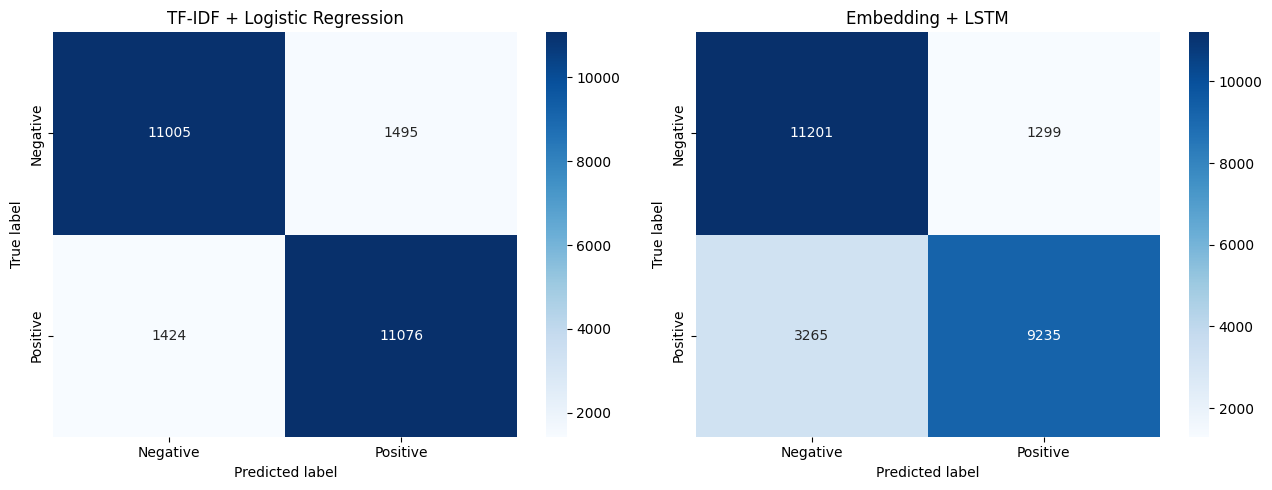

ML confusion matrix:
[[11005  1495]
 [ 1424 11076]]

DL confusion matrix:
[[11201  1299]
 [ 3265  9235]]


In [8]:
# Confusion matrices
cm_ml = confusion_matrix(y_true, y_pred_ml)
cm_dl = confusion_matrix(y_true, y_pred_dl)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm_ml,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    ax=axes[0],
)

axes[0].set_title("TF-IDF + Logistic Regression")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")

sns.heatmap(
    cm_dl,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    ax=axes[1],
)

axes[1].set_title("Embedding + LSTM")
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")

plt.tight_layout()
plt.show()

print("ML confusion matrix:")
print(cm_ml)

print("\nDL confusion matrix:")
print(cm_dl)

In [9]:
print("=" * 60)
print("MACHINE LEARNING: Classification Report")
print("=" * 60)

print(
    classification_report(
        y_true,
        y_pred_ml,
        target_names=["Negative", "Positive"],
        digits=4,
    )
)

print("=" * 60)
print("DEEP LEARNING: Classification Report")
print("=" * 60)

print(
    classification_report(
        y_true,
        y_pred_dl,
        target_names=["Negative", "Positive"],
        digits=4,
    )
)

MACHINE LEARNING: Classification Report
              precision    recall  f1-score   support

    Negative     0.8854    0.8804    0.8829     12500
    Positive     0.8811    0.8861    0.8836     12500

    accuracy                         0.8832     25000
   macro avg     0.8833    0.8832    0.8832     25000
weighted avg     0.8833    0.8832    0.8832     25000

DEEP LEARNING: Classification Report
              precision    recall  f1-score   support

    Negative     0.7743    0.8961    0.8307     12500
    Positive     0.8767    0.7388    0.8019     12500

    accuracy                         0.8174     25000
   macro avg     0.8255    0.8174    0.8163     25000
weighted avg     0.8255    0.8174    0.8163     25000



In [10]:
# Compare saved model sizes

model_paths = {
    "TF-IDF + Logistic Regression": ML_MODEL_PATH,
    "Embedding + LSTM": DL_MODEL_PATH,
}

model_sizes = []

for model_name, model_path in model_paths.items():
    size_bytes = model_path.stat().st_size

    model_sizes.append({
        "Model": model_name,
        "Size (MB)": size_bytes / (1024 ** 2),
        "Size (bytes)": size_bytes,
    })

model_size_df = pd.DataFrame(model_sizes).set_index("Model")

display(model_size_df.round(3))

,Size (MB),Size (bytes)
Model,,
TF-IDF + Logistic Regression,0.887,930020
Embedding + LSTM,11.609,12173411


In [11]:
# Calculate complete artifact sizes

ml_size_bytes = ML_MODEL_PATH.stat().st_size

dl_weights_bytes = DL_MODEL_PATH.stat().st_size
vocab_bytes = VOCAB_PATH.stat().st_size
dl_total_bytes = dl_weights_bytes + vocab_bytes

artifact_sizes = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Model file (MB)": ml_size_bytes / (1024 ** 2),
        "Additional files (MB)": 0,
        "Total required artifacts (MB)": ml_size_bytes / (1024 ** 2),
    },
    {
        "Model": "Embedding + LSTM",
        "Model file (MB)": dl_weights_bytes / (1024 ** 2),
        "Additional files (MB)": vocab_bytes / (1024 ** 2),
        "Total required artifacts (MB)": dl_total_bytes / (1024 ** 2),
    },
]).set_index("Model")

display(artifact_sizes.round(3))

print(
    "LSTM total artifacts are "
    f"{dl_total_bytes / ml_size_bytes:.2f} times the size of the ML model."
)

,Model file (MB),Additional files (MB),Total required artifacts (MB)
Model,,,
TF-IDF + Logistic Regression,0.887,0.00,0.887
Embedding + LSTM,11.609,0.51,12.120


LSTM total artifacts are 13.66 times the size of the ML model.


In [12]:
# Final comparison table

final_comparison = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy (%)": results.loc["TF-IDF + Logistic Regression", "Accuracy"] * 100,
        "Precision (%)": results.loc["TF-IDF + Logistic Regression", "Precision"] * 100,
        "Recall (%)": results.loc["TF-IDF + Logistic Regression", "Recall"] * 100,
        "F1-score (%)": results.loc["TF-IDF + Logistic Regression", "F1-score"] * 100,
        "Inference time (s)": ml_inference_time,
        "Latency (ms/review)": ml_inference_time / len(test_texts) * 1000,
        "Artifacts size (MB)": ml_size_bytes / (1024 ** 2),
    },
    {
        "Model": "Embedding + LSTM",
        "Accuracy (%)": results.loc["Embedding + LSTM", "Accuracy"] * 100,
        "Precision (%)": results.loc["Embedding + LSTM", "Precision"] * 100,
        "Recall (%)": results.loc["Embedding + LSTM", "Recall"] * 100,
        "F1-score (%)": results.loc["Embedding + LSTM", "F1-score"] * 100,
        "Inference time (s)": dl_inference_time,
        "Latency (ms/review)": dl_inference_time / len(test_texts) * 1000,
        "Artifacts size (MB)": dl_total_bytes / (1024 ** 2),
    },
]).set_index("Model")

display(final_comparison.round(3))


,Accuracy (%),Precision (%),Recall (%),F1-score (%),Inference time (s),Latency (ms/review),Artifacts size (MB)
Model,,,,,,,
TF-IDF + Logistic Regression,88.324,88.108,88.608,88.357,4.707,0.188,0.887
Embedding + LSTM,81.744,87.669,73.880,80.186,49.676,1.987,12.120


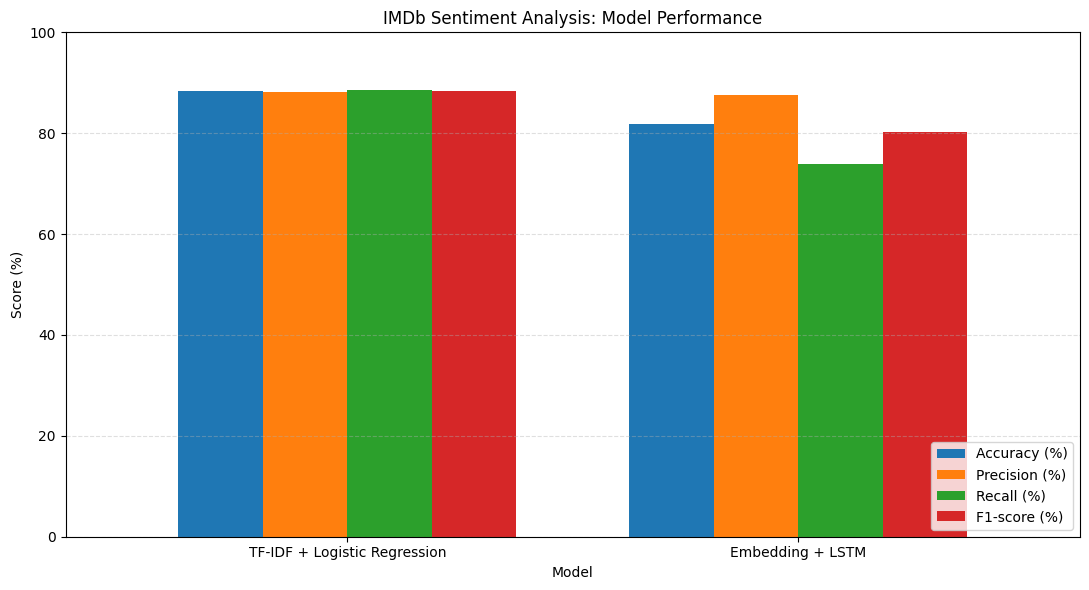

In [13]:
# Compare classification metrics

metrics = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-score (%)"]

plot_data = final_comparison[metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 100),
    width=0.75,
)

ax.set_title("IMDb Sentiment Analysis: Model Performance")
ax.set_ylabel("Score (%)")
ax.set_xlabel("Model")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


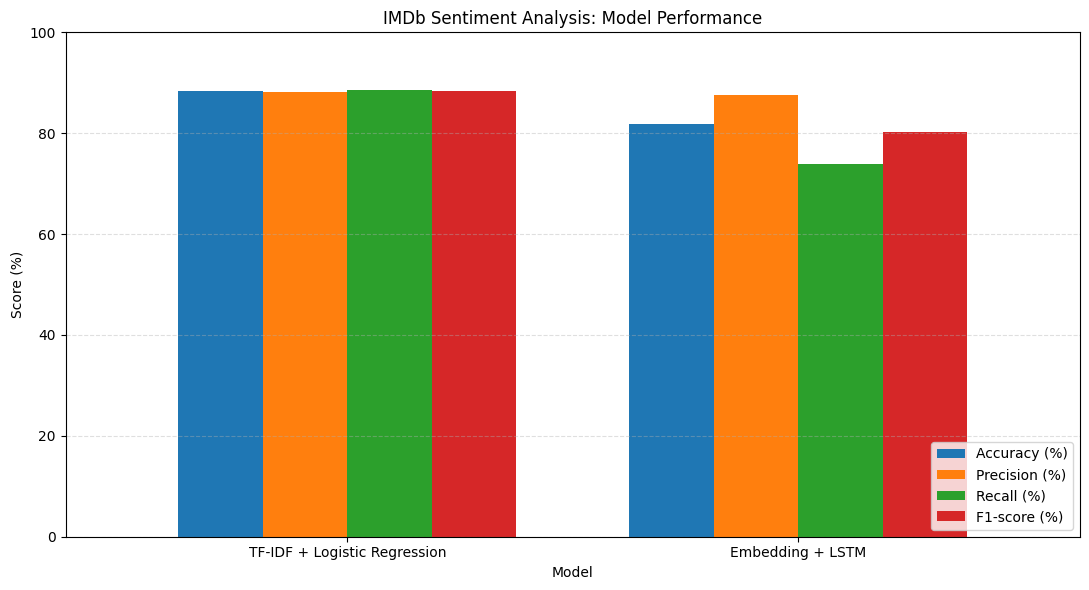

Saved plot to: d:\Python\Github_P\sentiment-analysis-deep-learning\comparison\model_performance.png


In [14]:
# Save the performance comparison plot

PLOT_PATH = PROJECT_ROOT / "comparison" / "model_performance.png"

fig = plot_data.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 100),
    width=0.75,
).get_figure()

ax = fig.axes[0]
ax.set_title("IMDb Sentiment Analysis: Model Performance")
ax.set_ylabel("Score (%)")
ax.set_xlabel("Model")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.tight_layout()
fig.savefig(PLOT_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("Saved plot to:", PLOT_PATH)